<a href="https://colab.research.google.com/github/Dhanwin007/langgraph_basics_1/blob/main/langgraph_hello_world.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from typing import TypedDict,Dict,List
from langgraph.graph import StateGraph,START,END #framework that helps you design and manage the flow of tasks and orchestrate the workflow among agents

In [4]:
#we should now build AgentState - A shared data structure that keeps track of the information as your application runs and proceeds
class AgentState(TypedDict):
  message:str
  name:str

def greeting_node(state:AgentState)->AgentState:
  state['message']="hi "+state['message']+" placed for 8lpa at europhins"
  return state

def complementing_node(state:AgentState)->AgentState:
  state['message']+=" Congratulations on getting placed at europhins "+state['name']
  return state

In [5]:
graph=StateGraph(AgentState)
graph.add_node("greeter",greeting_node)
graph.add_node("complementer",complementing_node)
graph.add_edge("greeter","complementer")
graph.set_entry_point("greeter")
graph.set_finish_point("complementer")
app=graph.compile()

In [6]:
result=app.invoke({"message":"Welcome","name":"ravi"})

In [7]:
result["message"]

'hi Welcome placed for 8lpa at europhins Congratulations on getting placed at europhins ravi'

In [8]:
class AgentState2(TypedDict):
  values:List[int]
  name:str
  result:str
  operation:str


In [9]:
import math
def process_values(state:AgentState2)->AgentState:
  """This fuction handles multiple different inputs"""
  if state["operation"]=="sum":
    state["result"]=f"Hi there {state["name"]} and the sum is {sum(state["values"])}"
  elif state["operation"]=="product":
    state["result"]=f"Hi there {state["name"]} and the sum is {math.prod(state["values"])}"
  return state

In [10]:
graph=StateGraph(AgentState2)
graph.add_node("processor",process_values)
graph.set_entry_point("processor")
graph.set_finish_point("processor")
app=graph.compile()

In [11]:
app.invoke({"values":[1,2,3,4,5],"name":"Dhanwin","operation":"product"})

{'values': [1, 2, 3, 4, 5],
 'name': 'Dhanwin',
 'result': 'Hi there Dhanwin and the sum is 120',
 'operation': 'product'}

In [12]:
class AgentState3(TypedDict):
  name:str
  age:int
  skills:List[str]
  message:str

In [13]:
def greeting(state:AgentState3)->AgentState3:
  """greeting function"""
  state["message"]=f"hi {state['name']}, Good Morning"
  return state
def age(state:AgentState3)->AgentState3:
  """age function"""
  state["message"]+=f" your age is {state['age']}"
  return state
def skills(state: AgentState3) -> AgentState3:
  """skills function"""
  skills_str = "\t".join(state["skills"])
  state["message"] += f" your skills are : {skills_str}"
  return state

In [14]:
graph=StateGraph(AgentState3)
graph.add_node("greeting",greeting)
graph.add_node("age",age)
graph.add_node("skills",skills)
graph.add_edge("greeting","age")
graph.add_edge("age","skills")
graph.set_entry_point("greeting")
graph.set_finish_point("skills")
app=graph.compile()


In [15]:
result=app.invoke({"name":"sharmila","age":21,"skills":["cheating","flirting","python","ml"]})
print(result["message"])

hi sharmila, Good Morning your age is 21 your skills are : cheating	flirting	python	ml


In [16]:
class AgentState4(TypedDict):
  number1:int
  number2:int
  operation1:str
  operation2:str
  number3:int
  number4:int
  result1:int
  result2:int

In [17]:
def adder(state:AgentState4)->AgentState4:
  """adder function"""
  state["result1"]=state["number1"]+state["number2"]
  return state
def subtractor(state:AgentState4)->AgentState4:
  """subtractor function"""
  state["result1"]=state["number1"]-state["number2"]
  return state
def adder2(state:AgentState4)->AgentState4:
  """adder function after second condition check"""
  state["result2"]=state["number3"]+state["number4"]
  return state
def subtractor2(state:AgentState4)->AgentState4:
  """subtractor function after second condition check"""
  state["result2"]=state["number3"]-state["number4"]
  return state
def decide_next_node(state:AgentState4)->AgentState4:
  "decides the next node to be taken based on the condition"
  if state["operation1"]=="add":
    return "addition_operation"
  elif state["operation1"]=="subtract":
    return "subtraction_operation"
def decide_next_operation(state:AgentState4)->AgentState4:
  if state["operation2"]=="add":
    return "addition_operation2"
  elif state["operation2"]=="subtract":
    return "subtraction_operation2"


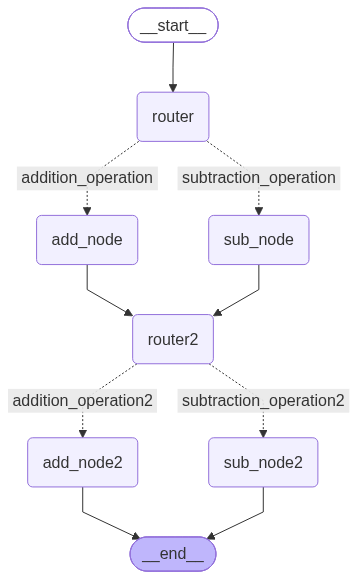

In [18]:
graph=StateGraph(AgentState4)
graph.add_node("add_node",adder)
graph.add_node("sub_node",subtractor)
graph.add_node("add_node2",adder2)
graph.add_node("sub_node2",subtractor2)
graph.add_node("router",lambda state:state)#passthrough function
graph.add_node("router2",lambda state:state)#passthrough function
graph.add_edge(START,"router")
graph.add_conditional_edges(
    "router",
    decide_next_node,

    {
        "addition_operation": "add_node",
        "subtraction_operation": "sub_node",
    },
)
graph.add_edge("add_node","router2")
graph.add_edge("sub_node","router2")
graph.add_conditional_edges(
    "router2",
    decide_next_operation,
    {
        "addition_operation2": "add_node2",
        "subtraction_operation2": "sub_node2",
    },
)
graph.add_edge("add_node2",END)
graph.add_edge("sub_node2",END)

graph.compile()

In [19]:
app=graph.compile()
result=app.invoke({"number1":10,"number2":5,"number3":15,"number4":5,"operation1":"subtract","operation2":"add"})
print(f"first conditional check:{result["result1"]} and after second conditionl check : {result["result2"]}")

first conditional check:5 and after second conditionl check : 20
